Installing/importing neccessary packages


In [2]:

# pip install pandas numpy matplotlib statsmodels scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

Loading the dataset and identifying the forecast horizon

In [3]:
DATA_PATH = "C:\\Users\\Admin\\Desktop\\DATA SCIENCE\\semester 3\\streaming data and time series analysis\\student_dataset (4).csv"

df = pd.read_csv(DATA_PATH)
df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.sort_values("time").reset_index(drop=True)

h = int(df["value"].isna().sum())      # how many missing at the end
train = df.iloc[:-h].copy()
future = df.iloc[-h:][["time"]].copy()

print("Total rows:", len(df))
print("Train rows:", len(train))
print("Forecast horizon h:", h)
print("Train end:", train["time"].iloc[-1])
print("Forecast start:", future["time"].iloc[0])

# sanity checks
dt = train["time"].diff().dropna().dt.total_seconds()
print("All steps are hourly:", bool((dt == 3600).all()))
print("Missing inside train:", int(train["value"].isna().sum()))

Total rows: 42767
Train rows: 41328
Forecast horizon h: 1439
Train end: 2019-12-31 23:00:01+00:00
Forecast start: 2020-01-01 00:00:01+00:00
All steps are hourly: True
Missing inside train: 0


Exploratory data analysis

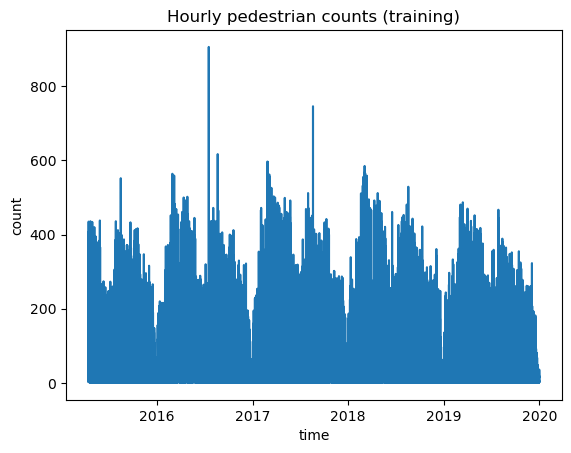

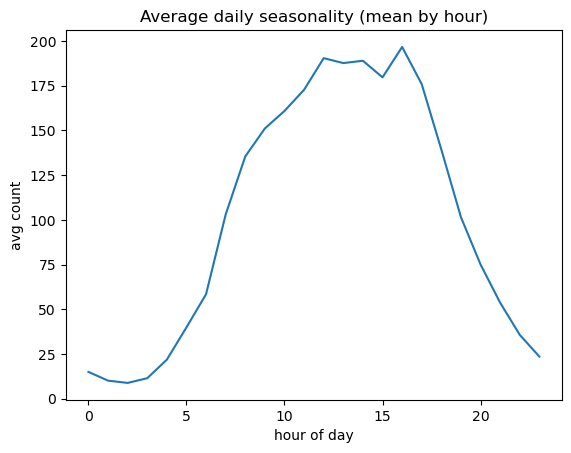

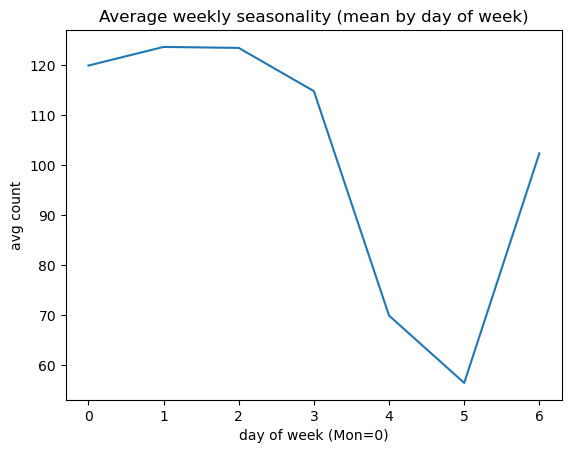

In [4]:
y = train["value"].astype(float).values

plt.figure()
plt.plot(train["time"], y)
plt.title("Hourly pedestrian counts (training)")
plt.xlabel("time"); plt.ylabel("count")
plt.show()

# average daily pattern
tmp = train.copy()
tmp["hour"] = tmp["time"].dt.hour
daily = tmp.groupby("hour")["value"].mean()

plt.figure()
plt.plot(daily.index, daily.values)
plt.title("Average daily seasonality (mean by hour)")
plt.xlabel("hour of day"); plt.ylabel("avg count")
plt.show()

# average weekly pattern
tmp["dow"] = tmp["time"].dt.dayofweek
weekly = tmp.groupby("dow")["value"].mean()

plt.figure()
plt.plot(weekly.index, weekly.values)
plt.title("Average weekly seasonality (mean by day of week)")
plt.xlabel("day of week (Mon=0)"); plt.ylabel("avg count")
plt.show()

Treatment: log1p transform (for ARIMA + UCM).
I apply log1p to stabilize variance and ensure forecasts remain nonnegative after inverse transform

In [5]:
y_log = np.log1p(y)

Model 1: ARIMA (SARIMA) forecasting

Fitting a seasonal ARIMA (daily seasonality = 24)

In [6]:
arima = sm.tsa.statespace.SARIMAX(
    y_log,
    order=(1,0,1),
    seasonal_order=(1,1,1,24),
    trend="n",
    enforce_stationarity=False,
    enforce_invertibility=False
)

arima_res = arima.fit(disp=False)

print("ARIMA AIC:", arima_res.aic)


ARIMA AIC: 50972.303320847925


Residual diagnostics

In [7]:
resid = arima_res.resid

# Ljung-Box: if p-values are large -> residuals closer to white noise
lb = acorr_ljungbox(resid, lags=[24, 48, 168], return_df=True)
print(lb)


         lb_stat  lb_pvalue
24   1576.944866        0.0
48   2345.340856        0.0
168  7670.486277        0.0


Forecast h steps and invert transform

In [8]:
arima_fc_log = arima_res.get_forecast(steps=h).predicted_mean
arima_fc = np.expm1(arima_fc_log)
arima_fc = np.maximum(arima_fc, 0.0)


Model 2: UCM (Unobserved Components Model)

In [ ]:
ucm = sm.tsa.UnobservedComponents(
    y_log,
    level="local linear trend",
    freq_seasonal=[
        {"period": 24, "harmonics": 12},     # daily
        {"period": 168, "harmonics": 20}     # weekly
    ]
)

ucm_res = ucm.fit(disp=False, maxiter=200)
print("UCM AIC:", ucm_res.aic)


UCM AIC: 49711.26644539057


Forecast and invert

In [10]:
ucm_fc_log = ucm_res.get_forecast(steps=h).predicted_mean
ucm_fc = np.expm1(ucm_fc_log)
ucm_fc = np.maximum(ucm_fc, 0.0)


Model 3: ML model (Gradient Boosting) with time features + lags

Feature engineering function

In [11]:
def build_ml_frame(df_train: pd.DataFrame) -> pd.DataFrame:
    x = df_train.copy()
    x["hour"] = x["time"].dt.hour
    x["dow"] = x["time"].dt.dayofweek
    x["month"] = x["time"].dt.month
    x["dayofyear"] = x["time"].dt.dayofyear

    # cyclical encoding
    x["hour_sin"] = np.sin(2*np.pi*x["hour"]/24)
    x["hour_cos"] = np.cos(2*np.pi*x["hour"]/24)
    x["dow_sin"]  = np.sin(2*np.pi*x["dow"]/7)
    x["dow_cos"]  = np.cos(2*np.pi*x["dow"]/7)

    # lags
    for lag in [1, 24, 168]:
        x[f"lag_{lag}"] = x["value"].shift(lag)

    # rolling stats (shift(1) prevents leakage)
    x["roll_mean_24"]  = x["value"].shift(1).rolling(24).mean()
    x["roll_mean_168"] = x["value"].shift(1).rolling(168).mean()

    return x


Train/validation split (time-based) + fit model

In [12]:
ml_df = build_ml_frame(train[["time","value"]].copy())
ml_df = ml_df.dropna().reset_index(drop=True)

features = [
    "hour","dow","month","dayofyear",
    "hour_sin","hour_cos","dow_sin","dow_cos",
    "lag_1","lag_24","lag_168",
    "roll_mean_24","roll_mean_168"
]

X = ml_df[features]
y_ml = ml_df["value"].astype(float)

# time-based validation: last 4 weeks (~672 hours)
val_size = 24*7*4
X_train, X_val = X.iloc[:-val_size], X.iloc[-val_size:]
y_train, y_val = y_ml.iloc[:-val_size], y_ml.iloc[-val_size:]

ml_model = HistGradientBoostingRegressor(
    max_depth=8,
    learning_rate=0.05,
    max_iter=400,
    random_state=42
)
ml_model.fit(X_train, y_train)

val_pred = ml_model.predict(X_val)
print("ML validation MAE:", mean_absolute_error(y_val, val_pred))


ML validation MAE: 8.40593748311523


Recursive forecasting (to generate the future 1439 predictions)

In [13]:
history = train[["time","value"]].copy().reset_index(drop=True)
ml_forecasts = []

for t in future["time"]:
    temp = pd.concat([history, pd.DataFrame({"time":[t], "value":[np.nan]})], ignore_index=True)
    feat_row = build_ml_frame(temp).iloc[-1]

    X_row = feat_row[features].to_frame().T
    X_row = X_row.fillna(method="ffill", axis=1).fillna(0.0)

    pred = float(ml_model.predict(X_row)[0])
    pred = max(pred, 0.0)

    ml_forecasts.append(pred)
    history = pd.concat([history, pd.DataFrame({"time":[t], "value":[pred]})], ignore_index=True)

ml_fc = np.array(ml_forecasts)


Create the submission CSV (exact format required)

In [14]:
submission = future.copy()

# professor wants only time + 3 forecast columns
# keep time format as in dataset (yyyy-mm-dd hh:mm:ss)
submission["time"] = submission["time"].dt.strftime("%Y-%m-%d %H:%M:%S")

submission["ARIMA"] = arima_fc
submission["UCM"]   = ucm_fc
submission["ML"]    = ml_fc

OUT_PATH = "predictions_submission.csv"
submission.to_csv(OUT_PATH, index=False)

print("Saved:", OUT_PATH)
print(submission)


Saved: predictions_submission.csv
                      time      ARIMA        UCM          ML
41328  2020-01-01 00:00:01   2.220747   1.680164    8.097159
41329  2020-01-01 01:00:01   1.157423   0.925642    5.800146
41330  2020-01-01 02:00:01   0.953803   0.570931    5.145432
41331  2020-01-01 03:00:01   0.887991   0.283744    6.662328
41332  2020-01-01 04:00:01   1.088210   0.229081    7.520818
...                    ...        ...        ...         ...
42762  2020-02-29 18:00:01  25.672995  10.342793  122.544914
42763  2020-02-29 19:00:01  16.870775   7.715173  100.083936
42764  2020-02-29 20:00:01  14.504505   7.576133   78.013029
42765  2020-02-29 21:00:01   9.669591   5.486304   61.022608
42766  2020-02-29 22:00:01   5.415402   3.026483   42.644519

[1439 rows x 4 columns]


In [16]:

# Save to Desktop in multiple formats for easy access
import os

# Desktop path
desktop_path = os.path.expanduser("~/Desktop")

# Save as CSV
csv_file = os.path.join(desktop_path, "predictions_submission.csv")
submission.to_csv(csv_file, index=False)
print(f"✓ CSV saved: {csv_file}")

# Save as Excel (.xlsx) - requires openpyxl
try:
    excel_file = os.path.join(desktop_path, "predictions_submission.xlsx")
    submission.to_excel(excel_file, index=False, sheet_name="Forecasts")
    print(f"✓ Excel saved: {excel_file}")
except ImportError:
    print("(Install openpyxl for Excel support: pip install openpyxl)")

print(f"\n📊 Preview of submission ({len(submission)} rows):")
print(submission.head(10))
print("...")
print(submission.tail(5))
print(f"\nFile size: {len(submission)} forecast hours (~{len(submission)/24:.1f} days)")


✓ CSV saved: C:\Users\Admin/Desktop\predictions_submission.csv
✓ Excel saved: C:\Users\Admin/Desktop\predictions_submission.xlsx

📊 Preview of submission (1439 rows):
                      time      ARIMA        UCM         ML
41328  2020-01-01 00:00:01   2.220747   1.680164   8.097159
41329  2020-01-01 01:00:01   1.157423   0.925642   5.800146
41330  2020-01-01 02:00:01   0.953803   0.570931   5.145432
41331  2020-01-01 03:00:01   0.887991   0.283744   6.662328
41332  2020-01-01 04:00:01   1.088210   0.229081   7.520818
41333  2020-01-01 05:00:01   5.049813   1.890789   8.900869
41334  2020-01-01 06:00:01   7.437907   3.555932  10.376914
41335  2020-01-01 07:00:01  15.687566   8.060182  13.074923
41336  2020-01-01 08:00:01  22.966882  11.873056  19.095029
41337  2020-01-01 09:00:01  24.968461  15.239432  25.985561
...
                      time      ARIMA        UCM          ML
42762  2020-02-29 18:00:01  25.672995  10.342793  122.544914
42763  2020-02-29 19:00:01  16.870775   7.71517